# **Fase 2 · Primeiro contato técnico**
### *Carrega cada faixa do corpus, confere seus dados técnicos e gera forma de onda e espectrograma.*

(Nenhum modelo de reconhecimento de fala ou de detecção de eventos é executado neste caderno)

## **1. Preparação: conecta o Google Drive e confere se os cinco áudios estão na pasta**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import warnings
warnings.filterwarnings('ignore', message='PySoundFile failed')
warnings.filterwarnings('ignore', category=FutureWarning, module='librosa')

In [ ]:
import os

PASTA_AUDIOS = '/content/drive/MyDrive/escuta-cerrada-poc/audios'

for nome in sorted(os.listdir(PASTA_AUDIOS)):
    print(nome)

1. 27230 - Concentração trabalhista no estádio do Pacaembú - 01-05-1944.mp3
2. Dia de Verão Gaúcho.wav
3. 27240 - Doutrina policial - é a prostituição um mal necessário - 1944 - Experiência de gravação (B).mp3
4. 27698 - Ritmos de samba - Almirante.wav
5. Descobrimento do Brasil.mp4


## **2. Conferência dos dados técnicos dos arquivos**

 *Lê diretamente de cada arquivo o formato, a taxa de amostragem, o número de canais, taxa de bits e a duração, com o programa ffprobe, e reúne os resultados numa tabela. Serve para conferir os dados registrados na proveniência (fase 1) e para documentar a cadeia de transformações que separa o disco de acetato do arquivo digital submetido aos modelos.*

In [ ]:
import subprocess, json
import pandas as pd

def dados_tecnicos(caminho):
    """Lê os dados técnicos de um arquivo de áudio sem decodificá-lo."""
    comando = ['ffprobe', '-v', 'quiet', '-print_format', 'json',
               '-show_format', '-show_streams', caminho]
    saida = subprocess.run(comando, capture_output=True, text=True).stdout
    info = json.loads(saida)
    audio = [s for s in info['streams'] if s['codec_type'] == 'audio'][0]
    tem_video = any(s['codec_type'] == 'video' for s in info['streams'])
    return {
        'formato': audio['codec_name'],
        'taxa de amostragem (Hz)': int(audio['sample_rate']),
        'canais': audio['channels'],
        'taxa de bits (kbps)': round(int(info['format'].get('bit_rate', 0)) / 1000),
        'duração (s)': round(float(info['format']['duration']), 1),
        'tem vídeo?': tem_video,
    }

linhas = []
for nome in sorted(os.listdir(PASTA_AUDIOS)):
    dados = dados_tecnicos(os.path.join(PASTA_AUDIOS, nome))
    dados['arquivo'] = nome[:45]
    linhas.append(dados)

tabela = pd.DataFrame(linhas).set_index('arquivo')
tabela

,formato,taxa de amostragem (Hz),canais,taxa de bits (kbps),duração (s),tem vídeo?
arquivo,,,,,,
1. 27230 - Concentração trabalhista no esta,mp3,44100,2,320,335.2,False
2. Dia de Verão Gaúcho.wav,pcm_s24le,48000,2,2304,201.3,False
3. 27240 - Doutrina policial - é a prostitui,mp3,44100,2,320,361.7,False
4. 27698 - Ritmos de samba - Almirante.wav,pcm_s24le,48000,2,2306,64.9,False
5. Descobrimento do Brasil.mp4,aac,44100,2,52,441.3,False


**Resultado.** Os cinco arquivos estão em estéreo, embora os discos de origem fossem monofônicos. Formatos, taxas de bits e durações conferem com a proveniência. A exceção é a taxa de amostragem da faixa 05, que o Windows declara como 22,05 kHz e o ffprobe lê como 44,1 kHz.



### 2.1 Variante de AAC da faixa 05

Verifica qual variante do formato AAC foi usada na faixa 05, para explicar a diferença entre a taxa de amostragem declarada pelo Windows e a lida pelo ffprobe.




In [ ]:
info = json.loads(subprocess.run(
    ['ffprobe', '-v', 'quiet', '-print_format', 'json', '-show_streams',
     os.path.join(PASTA_AUDIOS, sorted(os.listdir(PASTA_AUDIOS))[4])],
    capture_output=True, text=True).stdout)
print(info['streams'][0].get('profile'))

HE-AAC


**Resultado.** HE-AAC. Essa variante codifica apenas parte das frequências e prevê a reconstrução estimada das demais na reprodução. O espectrograma da faixa (seção 7.4) mostra, porém, ausência total de energia acima de cerca de 4,5 kHz, sem sequer o ruído de superfície presente nas outras faixas. O efeito do processo de compressão foi, portanto, a supressão dos agudos, e não sua reconstrução.

## **3. Carregamento dos sinais e comparação entre canais**

*Carrega cada faixa como sinal, na taxa de amostragem original e sem misturar os canais, e compara o canal esquerdo com o direito. Como os discos de acetato eram monofônicos, a medida indica se a digitalização apenas duplicou um mesmo sinal nos dois canais ou se os canais diferem.*

In [ ]:
import librosa
import numpy as np

ARQUIVOS = sorted(os.listdir(PASTA_AUDIOS))

def carregar(n):
    """Carrega a faixa n (de 1 a 5) na taxa de amostragem original, preservando os dois canais."""
    caminho = os.path.join(PASTA_AUDIOS, ARQUIVOS[n - 1])
    sinal, taxa = librosa.load(caminho, sr=None, mono=False)
    return sinal, taxa

for n in range(1, 6):
    sinal, taxa = carregar(n)
    esquerdo, direito = sinal[0], sinal[1]
    diferenca = np.max(np.abs(esquerdo - direito))
    correlacao = np.corrcoef(esquerdo, direito)[0, 1]
    print(f"Faixa {n:02d} | diferença máxima entre canais: {diferenca:.4f} | correlação: {correlacao:.4f}")

Faixa 01 | diferença máxima entre canais: 2.0114 | correlação: -0.3254
Faixa 02 | diferença máxima entre canais: 1.9111 | correlação: 0.1106
Faixa 03 | diferença máxima entre canais: 1.6048 | correlação: -0.5258
Faixa 04 | diferença máxima entre canais: 1.9934 | correlação: 0.3682
Faixa 05 | diferença máxima entre canais: 0.0235 | correlação: 1.0000


**Resultado.** Nas faixas 01 a 04, os canais diferem bastante, com correlação baixa ou negativa. Na faixa 05, são cópias do mesmo sinal (correlação de 1,0), o que indica que essa cópia derivou de uma fonte monofônica e passou por uma cadeia de transformações distinta da das demais.

## **4. Soma e diferença entre os canais**

*Decompõe cada faixa no que os dois canais têm em comum (a soma, que equivale à média usada pelos modelos ao converter o áudio para mono) e no que os distingue (a diferença). Mede a energia de cada versão e permite escutá-las separadamente, para saber onde estão a voz e o ruído antes de decidir como entregar o áudio aos modelos.*

In [ ]:
def energia_db(x):
    """Energia média do sinal em decibéis (quanto maior, mais 'forte')."""
    return 10 * np.log10(np.mean(x ** 2) + 1e-12)

for n in range(1, 6):
    sinal, taxa = carregar(n)
    soma = (sinal[0] + sinal[1]) / 2
    diferenca = (sinal[0] - sinal[1]) / 2
    print(f"Faixa {n:02d} | soma: {energia_db(soma):6.1f} dB | diferença: {energia_db(diferenca):6.1f} dB")

Faixa 01 | soma:  -20.4 dB | diferença:  -17.5 dB
Faixa 02 | soma:  -23.8 dB | diferença:  -24.7 dB
Faixa 03 | soma:  -27.8 dB | diferença:  -22.8 dB
Faixa 04 | soma:  -20.2 dB | diferença:  -23.6 dB
Faixa 05 | soma:  -22.7 dB | diferença:  -88.4 dB


### 4.1 Escuta das quatro versões · faixa 03, de 0:00 a 0:30



In [ ]:
from IPython.display import Audio, display

sinal, taxa = carregar(3)
trecho = slice(0, 30 * taxa)
versoes = {
    'canal esquerdo': sinal[0],
    'canal direito': sinal[1],
    'soma (média dos canais)': (sinal[0] + sinal[1]) / 2,
    'diferença entre os canais': (sinal[0] - sinal[1]) / 2,
}
for nome, x in versoes.items():
    print(nome)
    display(Audio(x[trecho], rate=taxa))

### 4.2 Escuta das quatro versões · faixa 01, de 2:10 a 2:40

In [ ]:
sinal, taxa = carregar(1)
trecho = slice(130 * taxa, 160 * taxa)
versoes = {
    'canal esquerdo': sinal[0],
    'canal direito': sinal[1],
    'soma (média dos canais)': (sinal[0] + sinal[1]) / 2,
    'diferença entre os canais': (sinal[0] - sinal[1]) / 2,
}
for nome, x in versoes.items():
    print(nome)
    display(Audio(x[trecho], rate=taxa))

**Resultado.** Nas duas faixas, a voz (e, na faixa 01, o grito de "muito bem!") está na soma, enquanto a diferença contém sobretudo o giro e o chiado do disco. Os aplausos deixam algum resíduo na diferença, por serem sons fortes e de banda larga.

Os modelos receberão, portanto, a soma dos canais. Essa escolha tem uma consequência para o experimento, já que a condição "sem filtro" exclui de antemão a parte do ruído de superfície que está na diferença, e isso será declarado.

## **5. Forma de onda e espectrograma mel**

*Define uma função que desenha, para qualquer faixa ou trecho, a forma de onda e o espectrograma mel da soma dos canais, e salva a imagem na pasta figuras do Drive. O espectrograma mel é a representação que os modelos efetivamente recebem no lugar do som.*

In [ ]:
import matplotlib.pyplot as plt
import librosa.display

PASTA_FIGURAS = '/content/drive/MyDrive/escuta-cerrada-poc/figuras'

def figura(n, inicio=0, fim=None, salvar=True):
    """Forma de onda e espectrograma mel da faixa n (soma dos canais), entre inicio e fim, em segundos."""
    sinal, taxa = carregar(n)
    mono = (sinal[0] + sinal[1]) / 2
    if fim is None:
        fim = len(mono) / taxa
    trecho = mono[int(inicio * taxa):int(fim * taxa)]

    mel = librosa.feature.melspectrogram(y=trecho, sr=taxa, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    tempos = librosa.times_like(mel_db, sr=taxa) + inicio

    fig, eixos = plt.subplots(2, 1, figsize=(14, 7), sharex=True, layout='constrained')
    librosa.display.waveshow(trecho, sr=taxa, ax=eixos[0], offset=inicio)
    eixos[0].set_title(f'Faixa {n:02d} · forma de onda')
    eixos[0].set_ylabel('amplitude')
    eixos[0].set_xlabel('')
    img = librosa.display.specshow(mel_db, sr=taxa, x_coords=tempos,
                                   x_axis='time', y_axis='mel', ax=eixos[1])
    eixos[1].set_title('espectrograma mel')
    eixos[1].set_xlabel('tempo')
    eixos[1].xaxis.set_major_formatter(
      plt.FuncFormatter(lambda s, _: f'{int(s // 60)}:{s % 60:04.1f}'))
    fig.colorbar(img, ax=eixos, format='%+2.0f dB')

    if salvar:
        nome = f'faixa{n:02d}_{int(inicio)}-{int(fim)}s.png'
        fig.savefig(os.path.join(PASTA_FIGURAS, nome), dpi=150)
    plt.show()

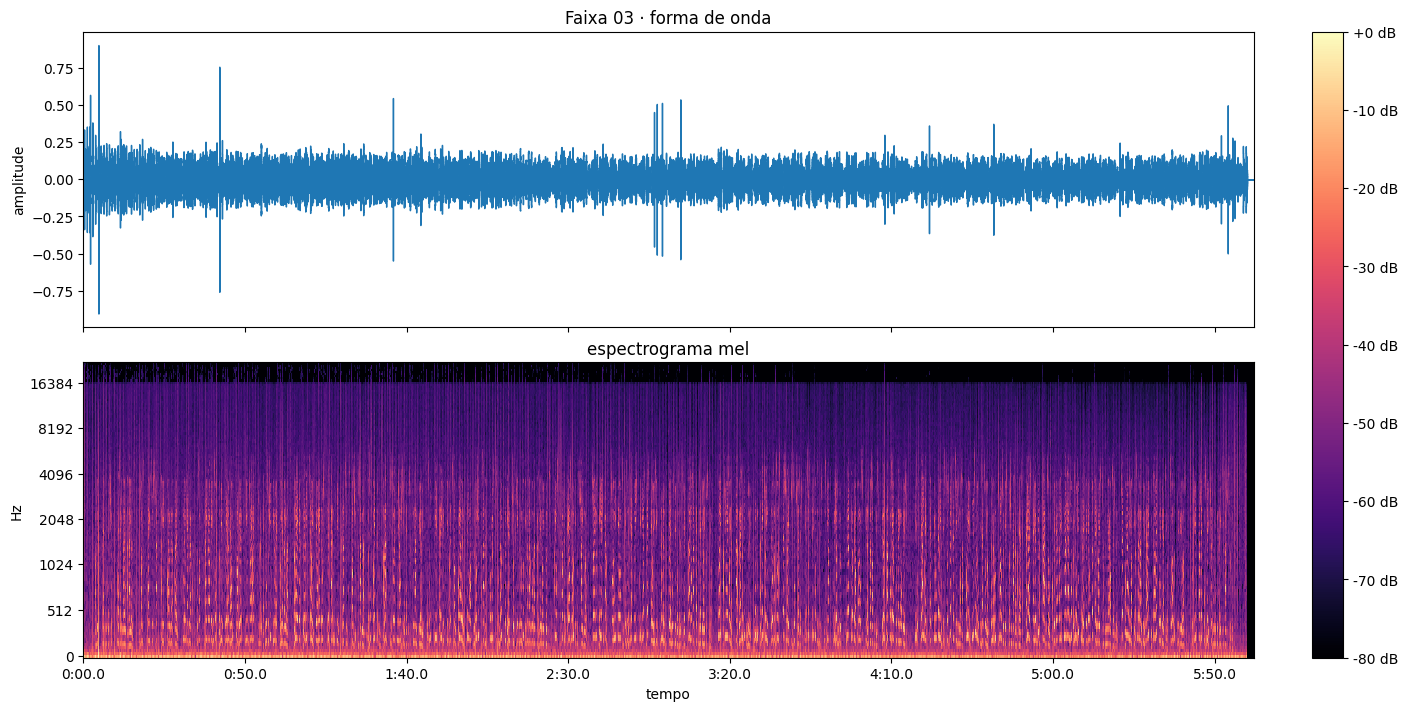

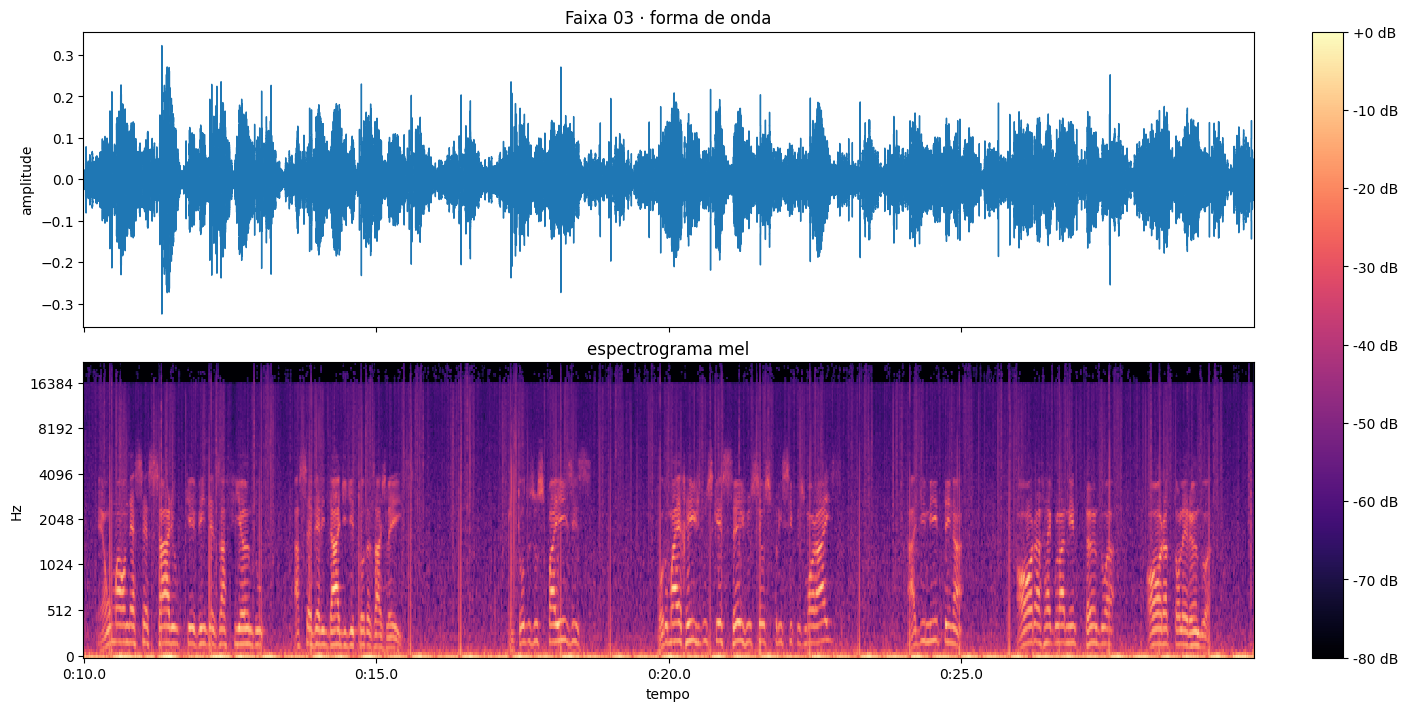

In [ ]:
figura(3)
figura(3, 10, 30)

**Resultado.** O espectrograma da faixa 03 mostra dois limites de frequência. A energia da voz se concentra abaixo de cerca de 4 kHz, limite provável da cadeia de gravação de 1944. Acima de cerca de 16 kHz há um corte abrupto, produzido pelo codificador MP3 na digitalização. Os picos mais altos da forma de onda são estalos do disco, muito visíveis na imagem e quase imperceptíveis à escuta.

## **6. Ver e ouvir trechos**

*Combina, para um mesmo trecho, a imagem e um tocador, para cruzar o que se vê com o que se ouve.*

In [ ]:
def ver_e_ouvir(n, inicio, fim):
    """Mostra forma de onda e espectrograma de um trecho e cria um tocador para ele."""
    figura(n, inicio, fim)
    sinal, taxa = carregar(n)
    mono = (sinal[0] + sinal[1]) / 2
    display(Audio(mono[int(inicio * taxa):int(fim * taxa)], rate=taxa))

### 6.1 Faixa 03 · virada de página

In [ ]:
ver_e_ouvir(3, 250, 262)

In [ ]:
ver_e_ouvir(3, 253, 259)

**Resultado.** A virada de página aparece na imagem como uma pausa da voz entre 4:14,9 e 4:17,15. Os dois ruídos de papel indicados pela escuta (4:15 e 4:16) coincidem com os dois traços de banda mais larga dessa pausa, por volta de 4:15,45 e 4:16,65, mas esses traços não se distinguem visualmente dos estalos do disco. A análise detalhada está no diário da fase 2.

## **7. Visão geral das cinco faixas**

*Desenha a forma de onda e o espectrograma mel de cada faixa inteira, para comparar a materialidade sonora dos registros (limites de frequência, ruído de superfície, estalos, pausas) e localizar trechos que merecem ser vistos e ouvidos em detalhe. A faixa 03 está na seção 5.*

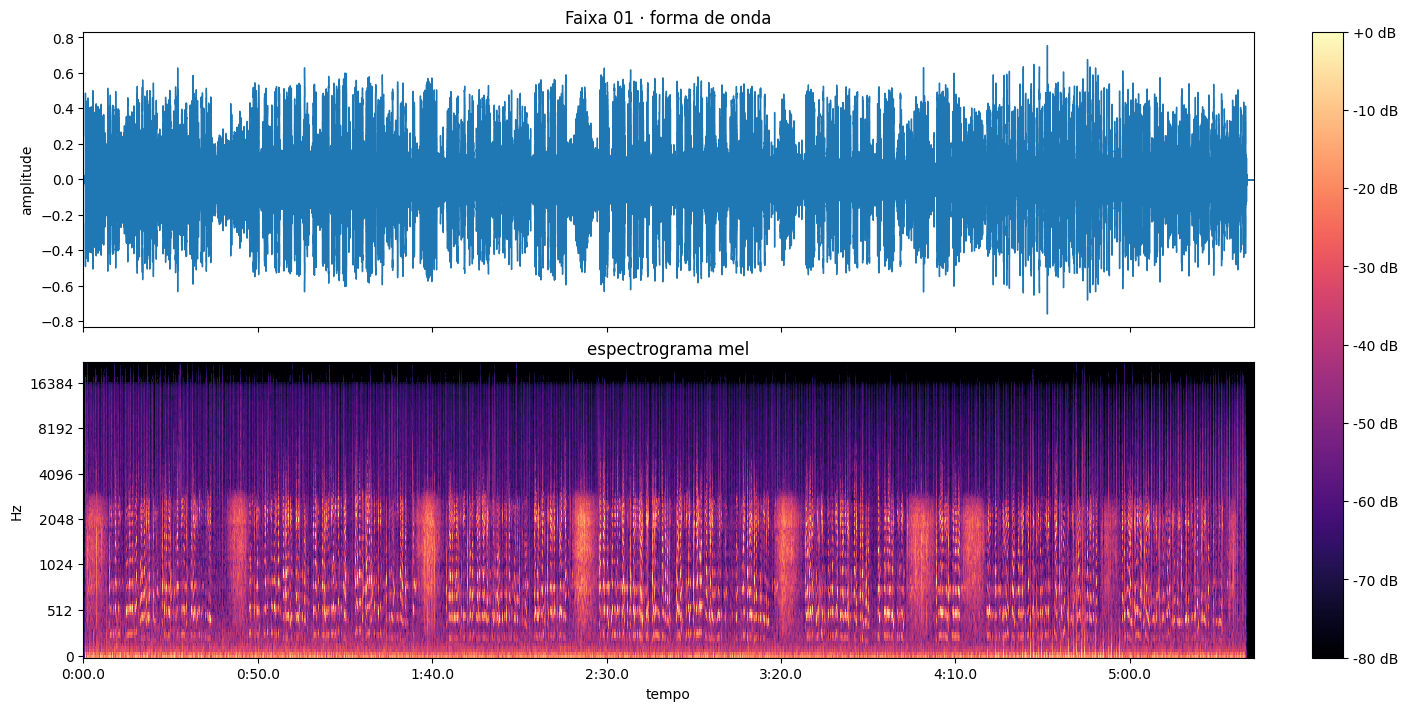

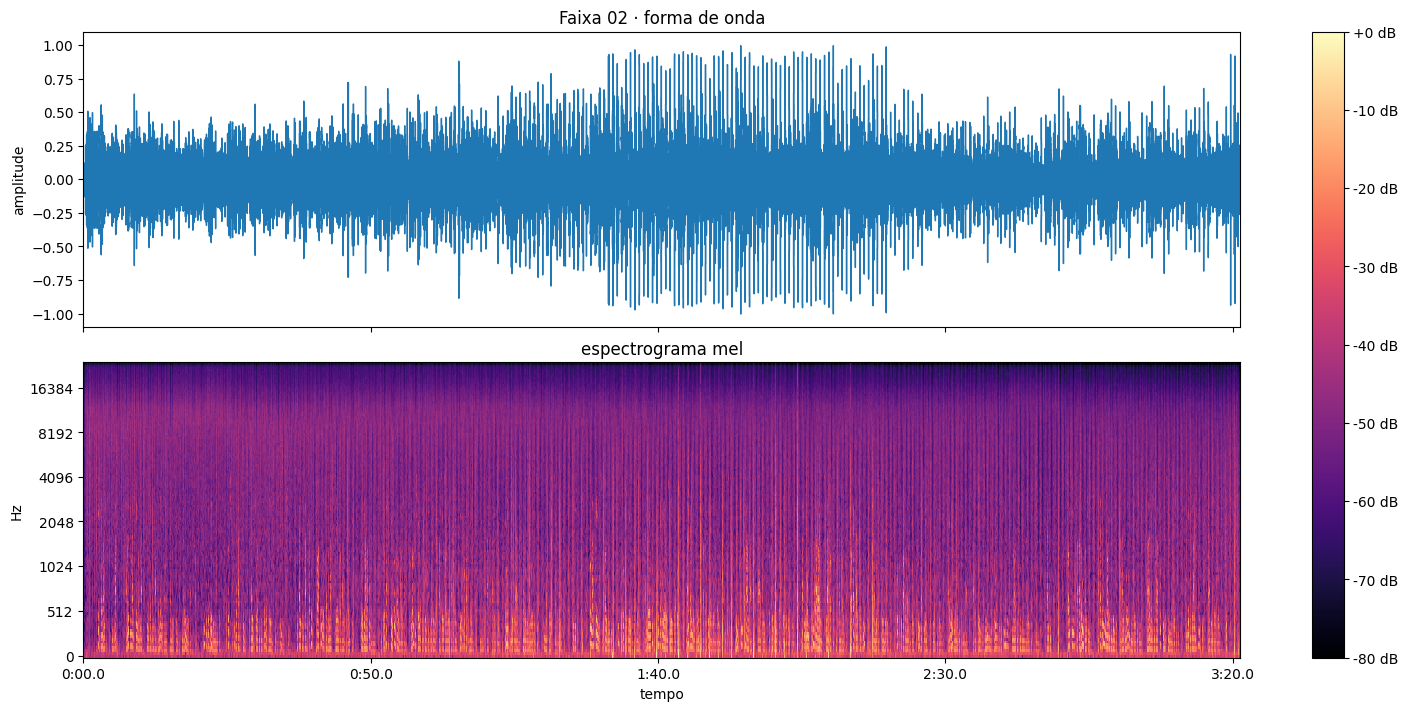

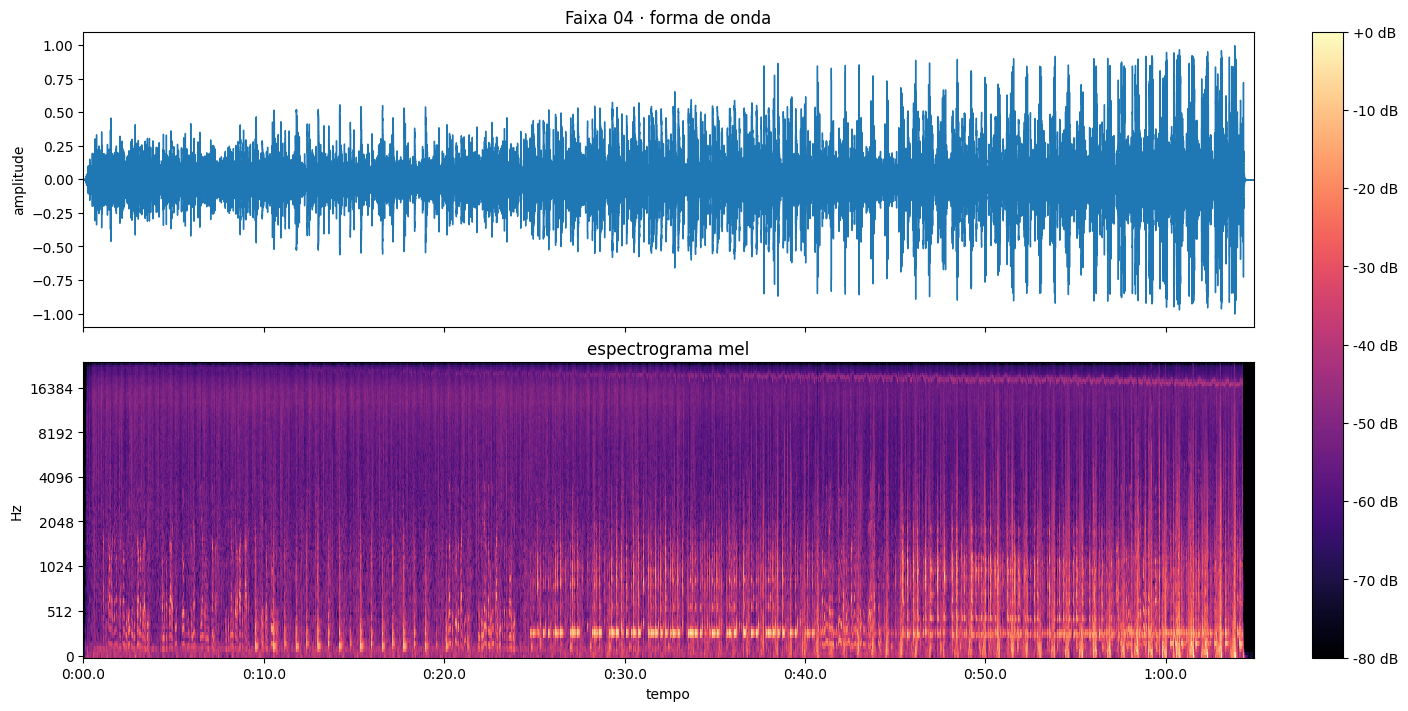

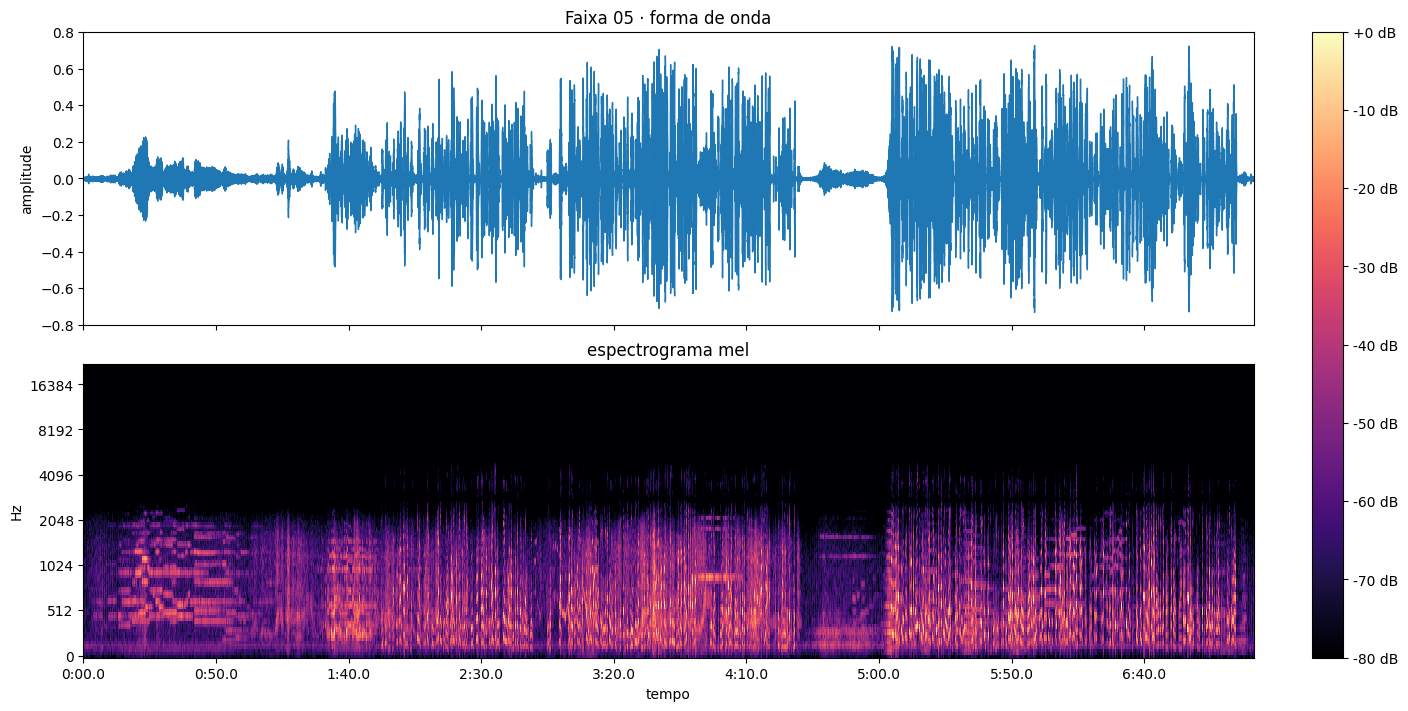

In [ ]:
for n in [1, 2, 4, 5]:
    figura(n)

### 7.1 Faixa 01 · Vargas no Pacaembu

In [ ]:
ver_e_ouvir(1, 2*60 + 10, 2*60 + 35)

In [ ]:
ver_e_ouvir(1, 2*60 + 12, 2*60 + 15)   # Vargas: vogais, consoantes e pausas
ver_e_ouvir(1, 2*60 + 17, 2*60 + 21)   # transição para o "muito bem!"

**Resultado.** O espectrograma distingue três tipos de presença sonora. A voz de Vargas, próxima do microfone, aparece como listras horizontais nítidas, regulares e empilhadas, interrompidas brevemente nas consoantes e de forma mais longa nas pausas da leitura. As vozes da plateia que gritam "muito bem!", distantes do microfone e emitidas em alturas diferentes, aparecem como arcos fracos e salpicados de laranja sobre um fundo predominantemente roxo. Os aplausos formam uma mancha densa e uniforme, sem listras, semelhante a um traço de giz de cera "deitado", e na forma de onda desenham um contorno contínuo que cresce e decresce, diferente dos picos separados da fala.

Ao longo da faixa há sete ou oito dessas manchas, algumas menos preenchidas que outras, e a transcrição registra sete passagens de aplauso. O "muito bem!" de 2:19, registrado na dissertação, ocorre exatamente nesse ponto do arquivo.

Voz e aplausos são interrompidos no mesmo limite superior, em torno de 3 kHz, embora palmas produzam, fora da gravação, energia em frequências muito mais altas. Esse limite pertence portanto à cadeia de gravação de 1944, e não às fontes sonoras. Acima de cerca de 16 kHz, o corte abrupto corresponde ao codificador MP3 da digitalização.

A imagem permite localizar as pausas com precisão, mas não informa a razão delas. A relação entre o ritmo das pausas e a leitura de um texto escrito é uma inferência da escuta, não um dado da representação.

### 7.2 Faixa 04 · Almirante

In [ ]:
ver_e_ouvir(4, 20, 30)   # a entrada da linha tracejada

In [ ]:
ver_e_ouvir(4, 38, 48)   # a mudança por volta de 0:43

**Resultado.** A fala de Almirante aparece como listras curvas, em três momentos (início da faixa, cerca de 0:21–0:23 e 0:40–0:44), sempre com um instrumento soando ao fundo e diminuindo de volume enquanto ele fala, o que indica um controle deliberado de intensidade durante a gravação. O primeiro tamborim, por ter afinação definida, desenha uma linha horizontal tracejada em torno de 250–300 Hz, em que cada traço corresponde a uma batida. O segundo tamborim, a partir de 0:45, não forma linha nítida e distribui energia numa faixa mais larga, com batidas mais cerradas. O surdo, muito grave, aparece pouco, comprimido na base da imagem. A forma de onda cresce ao longo da faixa, à medida que os instrumentos se acumulam.

A primeira hipótese levantada a partir da imagem atribuía a linha tracejada ao surdo. A escuta mostrou que se tratava do tamborim, o que confirma que a representação permite localizar padrões rítmicos, mas não identificar sozinha os instrumentos que os produzem.

O arquivo, em WAV sem compressão, não apresenta o corte do codificador MP3, e a imagem se estende até 24 kHz. Ainda assim, a energia musical raramente ultrapassa 2 a 4 kHz, limite da cadeia de gravação. Uma linha fina e ondulada entre 17 e 19 kHz, inaudível na escuta, corresponde provavelmente a um ruído eletrônico do equipamento de digitalização, já que a gravação de 1944 não registrava frequências tão altas.

### 7.3 Faixa 02 · Vargas Neto

In [ ]:
ver_e_ouvir(2, 80, 100)   # a passagem de "Madrugada" para "Meio-dia" (1:20 a 1:40)

#### Medição da velocidade de rotação do disco

Os estalos regulares ouvidos entre 1:32 e 2:16 indicam um defeito do disco que passa sob a agulha a cada volta. A célula transforma o trecho numa curva de impactos e compara essa curva com cópias de si mesma deslocadas no tempo (autocorrelação). O deslocamento em que a semelhança atinge o máximo corresponde ao intervalo entre duas passagens do defeito, ou seja, à duração de uma volta, a partir da qual se obtém a velocidade de rotação.

Período mais provável: 0.77 s → 78.1 repetições por minuto


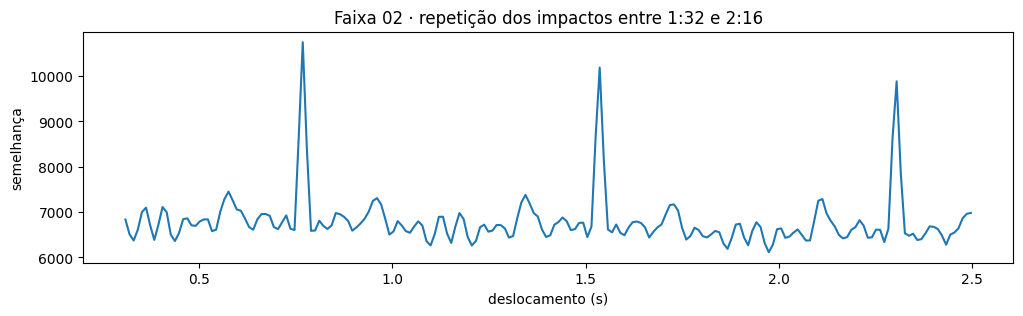

In [ ]:
sinal, taxa = carregar(2)
mono = (sinal[0] + sinal[1]) / 2
trecho = mono[int(92 * taxa):int(136 * taxa)]       # de 1:32 a 2:16, a região com estalos regulares

impactos = librosa.onset.onset_strength(y=trecho, sr=taxa)
quadros_por_segundo = taxa / 512
auto = librosa.autocorrelate(impactos)
atrasos = np.arange(len(auto)) / quadros_por_segundo

faixa = (atrasos > 0.3) & (atrasos < 2.5)
periodo = atrasos[faixa][np.argmax(auto[faixa])]
print(f"Período mais provável: {periodo:.2f} s → {60 / periodo:.1f} repetições por minuto")

plt.figure(figsize=(12, 3))
plt.plot(atrasos[faixa], auto[faixa])
plt.xlabel('deslocamento (s)')
plt.ylabel('semelhança')
plt.title('Faixa 02 · repetição dos impactos entre 1:32 e 2:16')
plt.show()

**Resultado.** É a faixa em que a voz aparece mais fraca em relação ao ruído. As listras da declamação são curtas e apagadas e raramente ultrapassam 1 a 1,5 kHz, limite mais baixo que o das faixas 01 e 03. O arquivo, em WAV sem compressão, não apresenta o corte do codificador MP3. A parte "Meio-dia" começa por volta de 1:25, como registrado na dissertação.

Entre cerca de 1:30 e 2:16, a forma de onda se torna mais intensa. A escuta mostrou que o aumento corresponde ao ruído do disco, e não a uma mudança na declamação, com um pequeno pulo no meio do trecho. Nessa região se ouvem estalos regulares, 26 em 20 segundos, produzidos por um defeito do disco que passa sob a agulha a cada volta. A autocorrelação dos impactos no mesmo trecho mede um período de 0,77 s, com picos também em 1,54 s e 2,31 s (duas e três voltas), o que corresponde a 78 rotações por minuto. A digitalização reproduziu o disco das faixas 02 e 04 a 78 rpm, e a altura natural das vozes indica que essa era também a velocidade de gravação.

### 7.4 Faixa 05 · Descobrimento do Brasil

In [ ]:
ver_e_ouvir(5, 3*60 + 45, 4*60 + 15)   # o sino e o que vem depois (3:45 a 4:15)

In [ ]:
ver_e_ouvir(5, 0, 30)   # o início, para o zumbido grave e a música

In [ ]:
ver_e_ouvir(5, 4*60 + 15, 4*60 + 40)   # passos (4:20) e vento (4:28)

**Resultado.** A faixa não contém nenhuma energia acima de cerca de 4,5 kHz, nem mesmo ruído de superfície, presente em todas as outras faixas. A maior parte do conteúdo fica abaixo de 2,5 kHz. A ausência resulta do processo de compressão desta cópia (HE-AAC a 52 kbps), que suprimiu os agudos.

A imagem permite distinguir os tipos de som encenados na gravação. A música aparece como traços horizontais retos, sustentados e dispostos em degraus, que acompanham a melodia; o sino, como um conjunto de traços horizontais simultâneos e prolongados, a partir de 3:52, tempo idêntico ao registrado na escuta cega; o vento, como uma nuvem difusa, sem traços, que cresce e diminui lentamente. A forma de onda acompanha a estrutura dramática, com início baixo, entrada das vozes por volta de 1:52, um intervalo quase sem fala entre 4:28 e 5:00 e um salto brusco de intensidade por volta de 5:02, no anúncio da terra avistada. Os passos de 4:20 aparecem como quatro riscos verticais regularmente espaçados. A regularidade dos impactos favorece a hipótese de passos, frente à de uma porta batendo, dúvida registrada na escuta cega.

Uma linha fraca entre 100 e 200 Hz atravessa a faixa inteira, inclusive antes da entrada da música, o que indica origem no equipamento de gravação ou de digitalização, e não no conteúdo encenado. Esse zumbido não consta da escuta cega e só passou a ser percebido depois de localizado no espectrograma. É o primeiro caso, no projeto, de uma representação computacional que dirige a atenção da escuta para algo antes não registrado. Como o espectrograma não é a saída de um modelo de classificação, o caso não se enquadra no critério de surpresa definido na fase 1, mas pertence ao mesmo tipo de fenômeno que o protocolo pretende examinar.

## **8. Ambiente de execução**

Registra a data da execução e as versões do Python, das bibliotecas e do ffprobe utilizadas, para que os resultados possam ser reproduzidos nas mesmas condições.

In [ ]:
import sys, matplotlib
from datetime import date

print('Data da execução:', date.today())
print('Python:', sys.version.split()[0])
for nome, modulo in [('librosa', librosa), ('numpy', np), ('pandas', pd), ('matplotlib', matplotlib)]:
    print(f'{nome}: {modulo.__version__}')

versao_ffprobe = subprocess.run(['ffprobe', '-version'], capture_output=True, text=True).stdout.splitlines()[0]
print(versao_ffprobe)

Data da execução: 2026-10-07
Python: 3.13.16
librosa: 0.11.0
numpy: 2.1.3
pandas: 2.2.3
matplotlib: 3.10.0
ffprobe version 6.1.1-3ubuntu5 Copyright (c) 2007-2023 the FFmpeg developers
